<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/quantum_hall_effect/qhe_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Quantum Hall Effect* — `qhe_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QHE Ch 3 Figures — Colab Notebook
**Quantum Hall Effect · Chapter 3: Fractional Quantum Hall Effect**

Tong (TIFR, Cambridge) · Output: `figures/ch03/fig0N_*.png`

## 수정 및 개선 사항 요약

| 그림 | 패널 | 분류 | 문제 | 수정 내용 |
|------|------|------|------|-----------|
| fig01 | Right (Laughlin |Ψ|²) | **오류** | Gaussian 인수 `exp(-r²/2ℓ²)` — Laughlin 파동함수 $\Psi\propto e^{-\sum|z_k|^2/4\ell^2}$에서 $z_2=0$ 고정 시 인수는 `exp(-r²/4ℓ²)`. 피크 위치가 $\sqrt{2m}\ell_B$ (코드) vs $2\sqrt{m}\ell_B$ (정확) | `exp(-r²/4ℓ²)` 로 수정 |
| fig02 | Middle (quasi-hole) | **오류** | 동일한 Gaussian 인수 오류 `exp(-r²/2ℓ²)` → 밀도 프로파일 폭이 절반으로 좁게 표시 | `exp(-r²/4ℓ²)` 로 수정 |
| fig05 | Left (hierarchy tree) | **오류** | `3/10`, `4/13`은 표준 Jain 또는 위계 FQHE 분수가 아님. $p=2$ 시퀀스 ($n/(4n-1)$) 분수여야 함 | `3/11`, `4/15` 으로 교체 ($p=2$, $n=3,4$: $3/11$, $4/15$ ✓) |
| fig05 | Middle (σ_xy vs B) | **경고** | $n=2\times10^{11}$ cm$^{-2}$ 에서 $\nu=1/3$: $B\approx24.8$ T — `xlim=(0.3,15)` 밖에 있어 FQHE 플래토 미표시 | $n=5\times10^{11}$ cm$^{-2}$, `xlim→25 T`로 확장, FQHE 플래토 표시 |
| fig03 | Left (CF B*) | **경고** | `fill_between`이 $p=1$ 분기만 칠해 $p=2$ 분기($1-4\nu$)의 부호 영역이 시각적으로 구분 안 됨 | $p=2$ 분기에도 `fill_between` 추가 |
| fig01 | Right (Laughlin |Ψ|²) | **경고** | `cmap='Blues'` — 어두운 배경에서 대비 부족 | `cmap='magma'` |
| fig02 | Middle (quasi-hole) | **경고** | `cmap='Blues'` — 동일 문제 | `cmap='magma'` |

**시인성 공통 개선**: minor tick 활성화, axes linewidth 강화, `tight_layout` 여백 증가, `figure.dpi=110`


---
## fig01 · FQHE Plateaux & Laughlin Wavefunction (§3.1)

**Left**: FQHE plateau structure — Jain sequence $\nu=n/(2n\pm1)$  
**Middle**: Laughlin pair correlation $g(r)\propto r^{2m}e^{-r^2/2\ell_B^2}$ — $m$-th order zero  
**Right**: 2D density $|\Psi_3|^2\propto|z_1-z_2|^6$ — electrons avoid each other

  saved -> figures/ch03/fig01_fqhe_laughlin.png


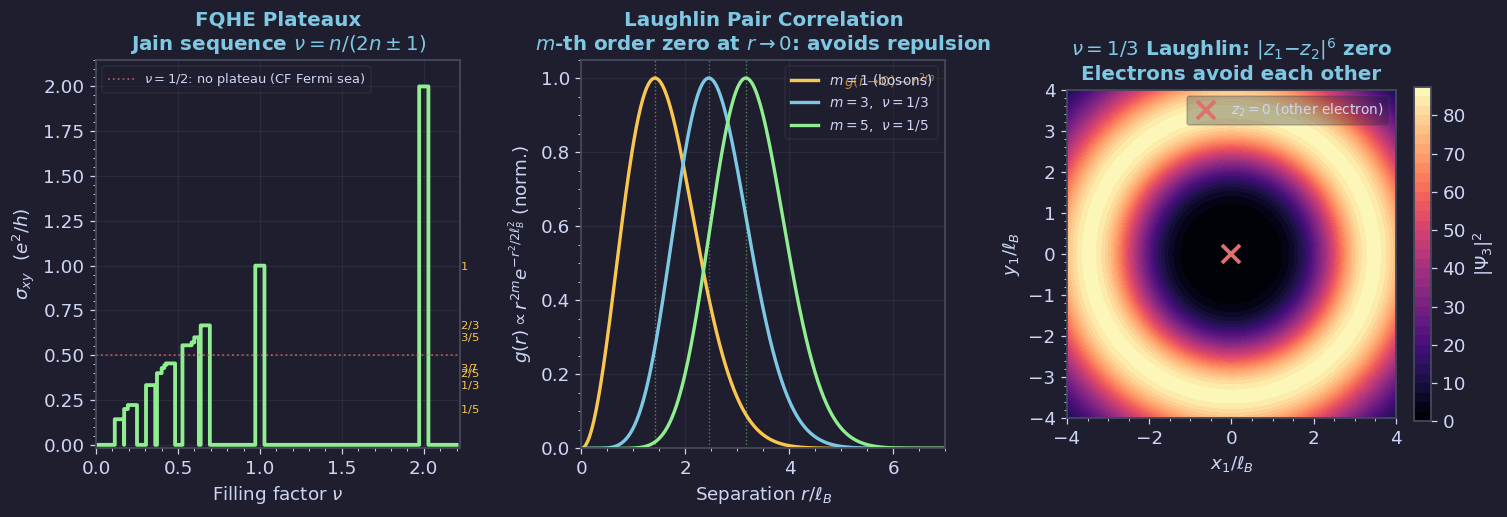

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import factorial
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01 · FQHE plateaux & Laughlin wavefunction properties ─────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: FQHE sigma_xy plateaux vs filling (Jain sequence, p=1)
ax = axes[0]
fracs = [1/3, 2/5, 3/7, 4/9, 5/11,
         2/3, 3/5, 4/7, 5/9,
         1/5, 2/9, 1/7,
         1.0, 2.0]
nu_arr = np.linspace(0, 2.2, 5000)
sig = np.zeros_like(nu_arr)
w = 0.028
for f in fracs:
    sig[np.abs(nu_arr - f) < w] = f
ax.step(nu_arr, sig, color=GREEN, lw=2.5, where='mid')
# Mark nu=1/2: no plateau
ax.axhline(0.5, color=RED, lw=1.2, ls=':', alpha=0.7,
           label=r'$\nu=1/2$: no plateau (CF Fermi sea)')
# Annotate key fractions
for f, lab in [(1/3,'1/3'),(2/5,'2/5'),(3/7,'3/7'),
               (2/3,'2/3'),(3/5,'3/5'),(1/5,'1/5'),(1.0,'1')]:
    ax.text(2.22, f, f'${lab}$', va='center', color=YELLOW, fontsize=7.5)
ax.set_xlabel(r'Filling factor $\nu$')
ax.set_ylabel(r'$\sigma_{xy}$  $(e^2/h)$')
ax.set_title('FQHE Plateaux\nJain sequence $\\nu=n/(2n\\pm1)$', color=BLUE)
ax.set_xlim(0, 2.22); ax.set_ylim(-0.02, 2.15)
ax.legend(fontsize=8.5, labelcolor=FG, loc='upper left')
ax.grid(True)

# Middle: Laughlin pair correlation g(r) vs r for m=1,3,5
ax2 = axes[1]
r = np.linspace(0.001, 7, 500); ell = 1.0
for m, col, lab in [(1, YELLOW, r'$m=1$ (bosons)'),
                    (3, BLUE,   r'$m=3$,  $\nu=1/3$'),
                    (5, GREEN,  r'$m=5$,  $\nu=1/5$')]:
    g = r**(2*m) * np.exp(-r**2 / (2*ell**2))
    g /= g.max()
    ax2.plot(r, g, color=col, lw=2.2, label=lab)
    r_pk = np.sqrt(2*m) * ell
    ax2.axvline(r_pk, color=col, lw=0.9, ls=':', alpha=0.5)
ax2.set_xlabel(r'Separation $r/\ell_B$')
ax2.set_ylabel(r'$g(r) \propto r^{2m} e^{-r^2/2\ell_B^2}$ (norm.)')
ax2.set_title('Laughlin Pair Correlation\n'+
              r'$m$-th order zero at $r\to0$: avoids repulsion', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True); ax2.set_xlim(0, 7); ax2.set_ylim(0, 1.05)
ax2.text(0.97, 0.97, r'$g(r\to0)\sim r^{2m}$',
         transform=ax2.transAxes, ha='right', va='top',
         color=ORANGE, fontsize=9)

# Right: Laughlin wavefunction zero structure
ax3 = axes[2]
# Show that |Psi|^2 ~ |z_1 - z_2|^{2m} — visualise as contour of |z1-z2|^{2m}
x3 = np.linspace(-4, 4, 300); y3 = x3
X3, Y3 = np.meshgrid(x3, y3)
# Fix z2=0, vary z1=X3+iY3
r2 = X3**2 + Y3**2
for m, ax_use, title in [(3, ax3, r'$|\Psi_3|^2 \propto |z_1{-}z_2|^6 e^{-r^2/2\ell_B^2}$')]:
    # Laughlin: Ψ∝exp(-Σ|z_k|²/4ℓ²); with z2=0 fixed → exp(-|z1|²/4ℓ²)
    psi2 = r2**m * np.exp(-r2 / (4*ell**2))
    im = ax3.contourf(X3, Y3, psi2, levels=40, cmap='magma')
    plt.colorbar(im, ax=ax3, label=r'$|\Psi_3|^2$', fraction=0.046).ax.yaxis.label.set_color(FG)
ax3.plot(0, 0, 'x', color=RED, ms=12, mew=2.5,
         label=r'$z_2=0$ (other electron)')
ax3.set_xlabel(r'$x_1/\ell_B$'); ax3.set_ylabel(r'$y_1/\ell_B$')
ax3.set_title(r'$\nu=1/3$ Laughlin: $|z_1{-}z_2|^6$ zero'+'\nElectrons avoid each other', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.set_aspect('equal')

plt.tight_layout(pad=1.5)
save('fig01_fqhe_laughlin.png', fig)


---
## fig02 · Plasma Analogy & Quasi-Holes (§3.1–3.2)

**Left**: Plasma analogy — $|\Psi_m|^2\sim e^{-\beta V_{\rm plasma}}$, $\beta=2/m$  
**Middle**: Quasi-hole wavefunction $\Psi_{\rm qh}\propto(z-\eta)\Psi_3$  
**Right**: Summary — fractional charge $e^*=e/m$ and anyonic statistics $\theta=\pi/m$

  saved -> figures/ch03/fig02_plasma_quasihole.png


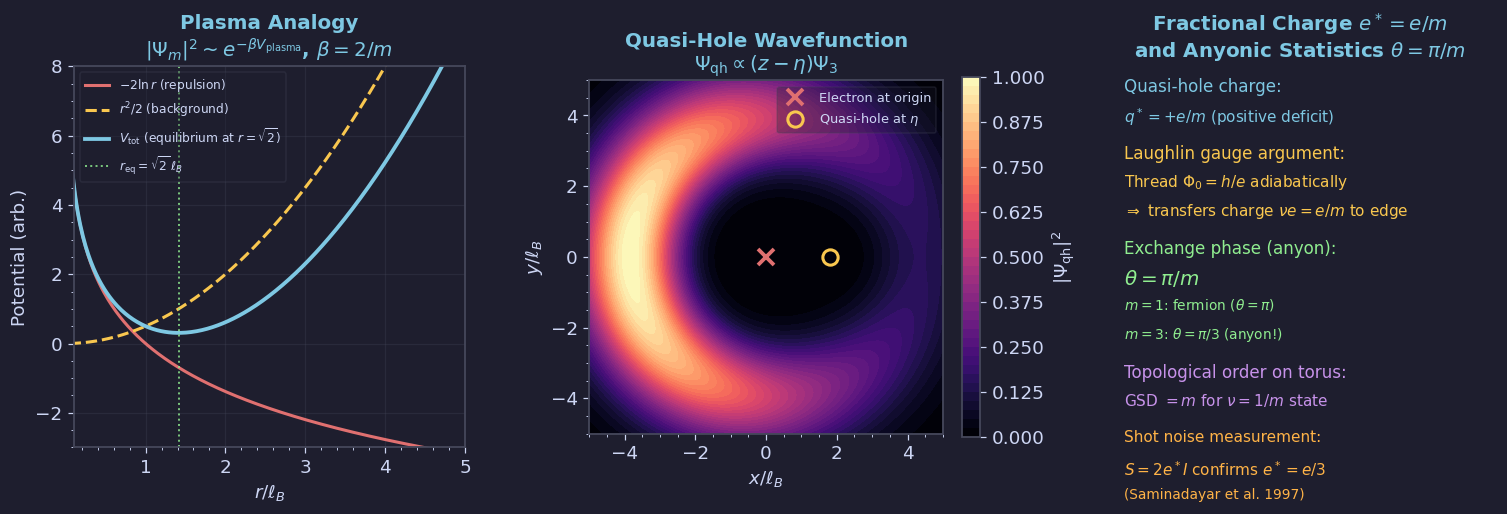

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import factorial
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02 · Plasma Analogy & Quasi-Holes ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Plasma analogy — log interaction between charges
ax = axes[0]
r = np.linspace(0.05, 5, 300)
ax.set_title('Plasma Analogy\n'+
             r'$|\Psi_m|^2 \sim e^{-\beta V_{\rm plasma}}$, $\beta=2/m$', color=BLUE)
# Electron-electron log repulsion (charge m in plasma units)
V_ee = -2 * np.log(r)          # 2D Coulomb: V ~ -2 ln r (repulsive for same sign)
# Background: uniform neutralising charge
V_bg = r**2 / (2)               # harmonic confinement from background
V_total = -2*np.log(r) + r**2/2
ax.plot(r, V_ee,    color=RED,    lw=2.0, label=r'$-2\ln r$ (repulsion)')
ax.plot(r, V_bg,    color=YELLOW, lw=2.0, ls='--', label=r'$r^2/2$ (background)')
ax.plot(r, V_total, color=BLUE,   lw=2.5, label=r'$V_{\rm tot}$ (equilibrium at $r=\sqrt{2}$)')
ax.axvline(np.sqrt(2), color=GREEN, lw=1.3, ls=':', alpha=0.8,
           label=r'$r_{\rm eq}=\sqrt{2}\,\ell_B$')
ax.set_xlabel(r'$r/\ell_B$'); ax.set_ylabel('Potential (arb.)')
ax.legend(fontsize=8, labelcolor=FG)
ax.grid(True); ax.set_xlim(0.1, 5); ax.set_ylim(-3, 8)

# Middle: Quasi-hole wavefunction — extra zero at eta
ax2 = axes[1]
x2 = np.linspace(-5, 5, 300); y2 = x2
X2, Y2 = np.meshgrid(x2, y2)
ell2 = 1.0
r2sq = X2**2 + Y2**2
# Laughlin m=3 pair correlation with quasi-hole at eta = (1.5, 0)
eta_x, eta_y = 1.8, 0.0
dist_eta2 = (X2 - eta_x)**2 + (Y2 - eta_y)**2
# |Psi_qh|^2 ~ |(z-eta)|^2 * |z|^{2*3} * exp(-|z|^2/2)
# Laughlin: single-particle Gaussian = exp(-|z|²/4ℓ²) with z2=0
psi_qh2 = dist_eta2 * r2sq**3 * np.exp(-r2sq / (4*ell2**2))
psi_qh2 /= psi_qh2.max()
im2 = ax2.contourf(X2, Y2, psi_qh2, levels=40, cmap='magma')
plt.colorbar(im2, ax=ax2, label=r'$|\Psi_{\rm qh}|^2$', fraction=0.046).ax.yaxis.label.set_color(FG)
ax2.plot(0,     0,     'x', color=RED,    ms=10, mew=2.5, label='Electron at origin')
ax2.plot(eta_x, eta_y, 'o', color=YELLOW, ms=10, mew=2,
         markerfacecolor='none', label=r'Quasi-hole at $\eta$')
ax2.set_xlabel(r'$x/\ell_B$'); ax2.set_ylabel(r'$y/\ell_B$')
ax2.set_title('Quasi-Hole Wavefunction\n'+
              r'$\Psi_{\rm qh}\propto(z-\eta)\Psi_3$', color=BLUE)
ax2.legend(fontsize=8.5, labelcolor=FG)
ax2.set_aspect('equal')

# Right: Fractional charge e* = e/m from adiabatic flux insertion
ax3 = axes[2]
ax3.axis('off')
ax3.set_title('Fractional Charge $e^*=e/m$\nand Anyonic Statistics $\\theta=\\pi/m$', color=BLUE)
items = [
    (r'Quasi-hole charge:', BLUE, 11),
    (r'$q^*=+e/m$ (positive deficit)', BLUE, 10),
    ('', FG, 8),
    ('Laughlin gauge argument:', YELLOW, 11),
    (r'Thread $\Phi_0=h/e$ adiabatically', YELLOW, 10),
    (r'$\Rightarrow$ transfers charge $\nu e = e/m$ to edge', YELLOW, 10),
    ('', FG, 8),
    ('Exchange phase (anyon):', GREEN, 11),
    (r'$\theta = \pi/m$', GREEN, 13),
    (r'$m=1$: fermion ($\theta=\pi$)', GREEN, 9),
    (r'$m=3$: $\theta=\pi/3$ (anyon!)', GREEN, 9),
    ('', FG, 8),
    ('Topological order on torus:', PURPLE, 11),
    (r'GSD $= m$ for $\nu=1/m$ state', PURPLE, 10),
    ('', FG, 8),
    ('Shot noise measurement:', ORANGE, 10),
    (r'$S=2e^*I$ confirms $e^*=e/3$', ORANGE, 10),
    ('(Saminadayar et al. 1997)', ORANGE, 9),
]
y_pos = 0.97
for txt, col, fs in items:
    ax3.text(0.05, y_pos, txt, transform=ax3.transAxes,
             color=col, fontsize=fs, va='top')
    y_pos -= 0.075 if txt else 0.025

plt.tight_layout(pad=1.5)
save('fig02_plasma_quasihole.png', fig)


---
## fig03 · Composite Fermions & Jain Sequence (§3.3)

**Left**: CF effective field $B^*=B(1-2p\nu)$ vs filling — zero at $\nu=1/(2p)$  
**Middle**: Jain sequence $\nu=n/(2n\pm1)$ for $p=1$ — both branches  
**Right**: Schematic phase diagram of the lowest Landau level

  saved -> figures/ch03/fig03_composite_fermions.png


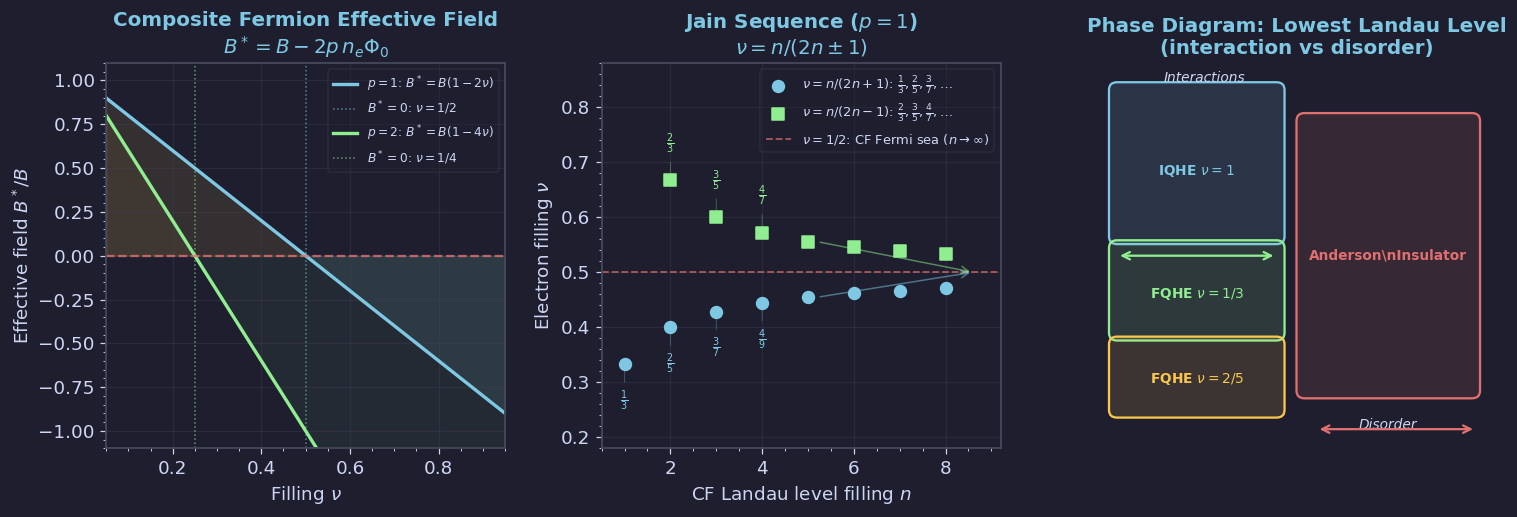

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import factorial
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03 · Composite Fermions & Jain Sequence ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: CF effective field B* vs filling nu (p=1 and p=2)
ax = axes[0]
nu = np.linspace(0.05, 0.95, 500)
for p, col, lab in [(1, BLUE,  r'$p=1$: $B^*=B(1-2\nu)$'),
                    (2, GREEN, r'$p=2$: $B^*=B(1-4\nu)$')]:
    Bs = 1.0 - 2*p*nu
    ax.plot(nu, Bs, color=col, lw=2.2, label=lab)
    nu0 = 1.0/(2*p)
    ax.axvline(nu0, color=col, lw=1.0, ls=':', alpha=0.6,
               label=f'$B^*=0$: $\\nu={1}/{2*p}$')
ax.axhline(0, color=RED, lw=1.5, ls='--', alpha=0.8)
# p=1 fill: B*/B>0 (yellow) and B*/B<0 (blue)
ax.fill_between(nu, 0, 1-2*nu, where=(1-2*nu) > 0, color=YELLOW, alpha=0.10)
ax.fill_between(nu, 0, 1-2*nu, where=(1-2*nu) < 0, color=BLUE,   alpha=0.10)
# p=2 fill: B*/B = 1-4nu
ax.fill_between(nu, 0, 1-4*nu, where=(1-4*nu) > 0, color=YELLOW, alpha=0.06)
ax.fill_between(nu, 0, 1-4*nu, where=(1-4*nu) < 0, color=GREEN,  alpha=0.06)
ax.set_xlabel(r'Filling $\nu$')
ax.set_ylabel(r'Effective field $B^*/B$')
ax.set_title('Composite Fermion Effective Field\n'+
             r'$B^*=B-2p\,n_e\Phi_0$', color=BLUE)
ax.legend(fontsize=8, labelcolor=FG, ncol=1)
ax.grid(True); ax.set_xlim(0.05, 0.95); ax.set_ylim(-1.1, 1.1)

# Middle: Jain sequence fractions for p=1
ax2 = axes[1]
# nu = n/(2pn+1) and n/(2pn-1) for p=1
p = 1
n_vals = np.arange(1, 9)
nu_plus  = n_vals / (2*p*n_vals + 1)   # n/(2n+1)
nu_minus = n_vals / (2*p*n_vals - 1)   # n/(2n-1)  (n>=2 for denom>0)
nu_minus = nu_minus[n_vals >= 2]
n_minus  = n_vals[n_vals >= 2]

ax2.scatter(n_vals,  nu_plus,  color=BLUE,  s=60, zorder=5,
            label=r'$\nu=n/(2n+1)$: $\frac{1}{3},\frac{2}{5},\frac{3}{7},\ldots$')
ax2.scatter(n_minus, nu_minus, color=GREEN, s=60, zorder=5, marker='s',
            label=r'$\nu=n/(2n-1)$: $\frac{2}{3},\frac{3}{5},\frac{4}{7},\ldots$')
# 라벨 전략:
#   nu_plus  (동그라미, BLUE)  → 점 아래쪽에 표기
#   nu_minus (네모,    GREEN) → 점 위쪽에 표기
#   n=1~4만 표기; n>=5는 수렴 구간으로 '→ 1/2' 안내선만 표시
for n, nu_p in zip(n_vals, nu_plus):
    if n <= 4:
        ax2.annotate(f'$\\frac{{{n}}}{{{2*n+1}}}$',
                     xy=(n, nu_p), xytext=(0, -16),
                     textcoords='offset points',
                     ha='center', va='top', color=BLUE, fontsize=9,
                     arrowprops=dict(arrowstyle='-', color=BLUE, lw=0.5, alpha=0.4))
for n, nu_m in zip(n_minus, nu_minus):
    if n <= 4:
        ax2.annotate(f'$\\frac{{{n}}}{{{2*n-1}}}$',
                     xy=(n, nu_m), xytext=(0, +16),
                     textcoords='offset points',
                     ha='center', va='bottom', color=GREEN, fontsize=9,
                     arrowprops=dict(arrowstyle='-', color=GREEN, lw=0.5, alpha=0.4))
# n>=5: 수렴을 화살표로 표현
ax2.annotate('', xy=(8.6, 0.500), xytext=(5.2, nu_plus[4]),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.0, alpha=0.5))
ax2.annotate('', xy=(8.6, 0.500), xytext=(5.2, nu_minus[3]),
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.0, alpha=0.5))
ax2.axhline(0.5, color=RED, lw=1.2, ls='--', alpha=0.7,
            label=r'$\nu=1/2$: CF Fermi sea ($n\to\infty$)')
ax2.set_xlabel('CF Landau level filling $n$')
ax2.set_ylabel(r'Electron filling $\nu$')
ax2.set_title('Jain Sequence ($p=1$)\n'+
              r'$\nu=n/(2n\pm1)$', color=BLUE)
ax2.legend(fontsize=8.5, labelcolor=FG, loc='upper right')
ax2.grid(True); ax2.set_xlim(0.5, 9.2); ax2.set_ylim(0.18, 0.88)

# Right: Phase diagram of the first Landau level
ax3 = axes[2]
ax3.set_xlim(0, 1); ax3.set_ylim(0, 1); ax3.axis('off')
ax3.set_title('Phase Diagram: Lowest Landau Level\n'+
              '(interaction vs disorder)', color=BLUE)
# Draw phase regions schematically
from matplotlib.patches import FancyBboxPatch
regions = [
    (0.05, 0.55, 0.4, 0.38, BLUE,   r'IQHE $\nu=1$',     0.25, 0.72),
    (0.05, 0.30, 0.4, 0.22, GREEN,  r'FQHE $\nu=1/3$',   0.25, 0.40),
    (0.05, 0.10, 0.4, 0.17, YELLOW, r'FQHE $\nu=2/5$',   0.25, 0.18),
    (0.52, 0.15, 0.42,0.70, RED,    r'Anderson\nInsulator', 0.73, 0.50),
]
for x,y,w,h,col,lab,tx,ty in regions:
    rect = FancyBboxPatch((x,y),w,h,
                          boxstyle='round,pad=0.02',
                          facecolor=col+'22', edgecolor=col, lw=1.5)
    ax3.add_patch(rect)
    ax3.text(tx, ty, lab, ha='center', va='center',
             color=col, fontsize=9, fontweight='bold',
             transform=ax3.transAxes)
ax3.text(0.27, 0.95, 'Interactions', ha='center', color=FG, fontsize=9,
         transform=ax3.transAxes, style='italic')
ax3.text(0.73, 0.05, 'Disorder', ha='center', color=FG, fontsize=9,
         transform=ax3.transAxes, style='italic')
ax3.annotate('', xy=(0.45,0.5), xytext=(0.05,0.5),
             arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5),
             xycoords='axes fraction', textcoords='axes fraction')
ax3.annotate('', xy=(0.95,0.05), xytext=(0.55,0.05),
             arrowprops=dict(arrowstyle='<->', color=RED, lw=1.5),
             xycoords='axes fraction', textcoords='axes fraction')

plt.tight_layout(pad=1.5)
save('fig03_composite_fermions.png', fig)


---
## fig04 · Anyonic Statistics & Topological Order (§3.2)

**Left**: Statistical phase $\theta=\pi/m$ vs filling $\nu=1/m$ — anyons between bosons & fermions  
**Middle**: Braid diagram — exchanging two anyons gives phase $e^{i\theta}$  
**Right**: Ground-state degeneracy $m$ on torus — signature of topological order

  saved -> figures/ch03/fig04_anyons_topo_order.png


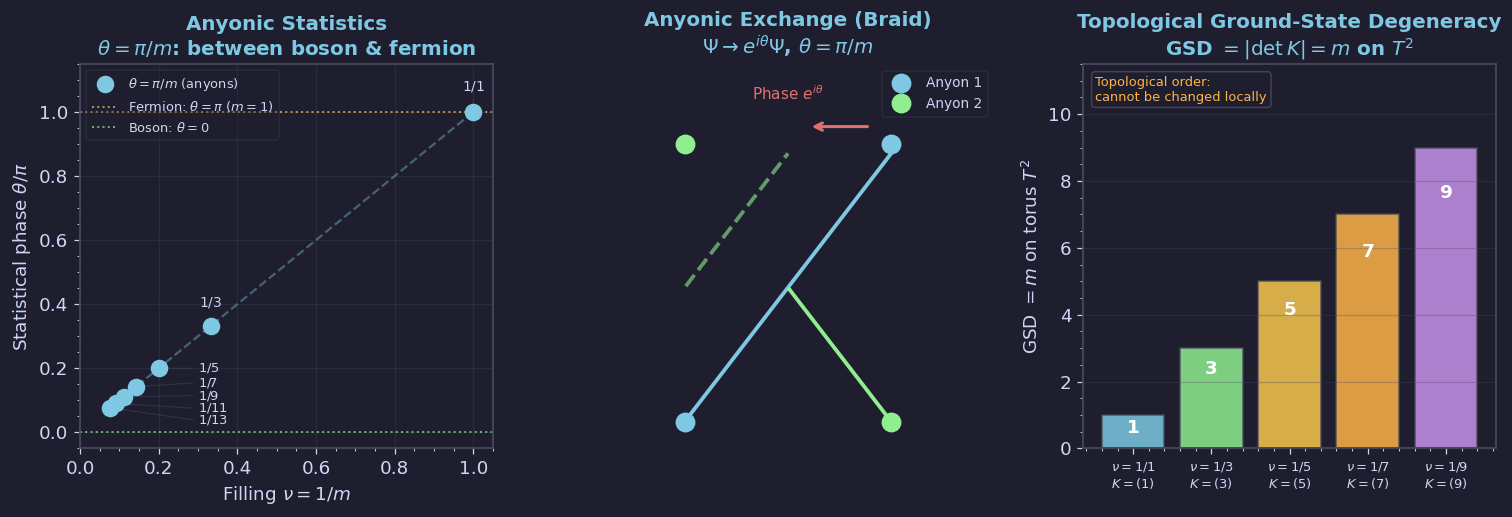

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import factorial
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04 · Anyonic Statistics & Topological Order ────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Statistical phase theta = pi/m vs filling nu = 1/m
ax = axes[0]
m_vals = np.arange(1, 14, 2)
nu_vals = 1.0 / m_vals
theta   = np.pi / m_vals
ax.scatter(nu_vals, theta / np.pi, color=BLUE, s=110, zorder=5,
           label=r'$\theta = \pi/m$ (anyons)')
ax.plot(nu_vals, theta / np.pi, color=BLUE, lw=1.5, ls='--', alpha=0.4)
ax.axhline(1.0, color=YELLOW, lw=1.3, ls=':', alpha=0.7,
           label=r'Fermion: $\theta=\pi$ ($m=1$)')
ax.axhline(0.0, color=GREEN,  lw=1.3, ls=':', alpha=0.7,
           label=r'Boson: $\theta=0$')
# 라벨 전략:
#   m=1 (nu=1.00): 점 바로 위 (공간 충분)
#   m=3 (nu=0.33): 점 위
#   m=5~13 (nu=0.08~0.20): 밀집 → 오른쪽 여백(nu~0.28~0.40)에 세로 배열 후 인출선
_spread_ms   = [5, 7, 9, 11, 13]
_spread_y    = [0.20, 0.155, 0.115, 0.075, 0.038]   # 균등 배분 y 좌표
_spread_x    = 0.30                                   # 라벨 x 고정 위치

# m=1, 3: 점 근처 직접 표기
for nu, th, m in zip(nu_vals[:2], theta[:2]/np.pi, m_vals[:2]):
    dy = 12 if m == 1 else 10
    ax.annotate(f'$1/{m}$', (nu, th),
                xytext=(0, dy), textcoords='offset points',
                fontsize=9, color=FG, ha='center', va='bottom',
                arrowprops=dict(arrowstyle='-', color=EDGE, lw=0.5, alpha=0.4))

# m=5~13: 오른쪽에 균등 배열
for m, ly in zip(_spread_ms, _spread_y):
    nu_pt = 1.0 / m
    th_pt = 1.0 / m   # theta/pi = 1/m
    # 라벨 텍스트
    ax.text(_spread_x, ly, f'$1/{m}$',
            ha='left', va='center', fontsize=8.5, color=FG)
    # 인출선: 라벨에서 점으로
    ax.annotate('', xy=(nu_pt, th_pt),
                xytext=(_spread_x - 0.005, ly),
                arrowprops=dict(arrowstyle='-', color=EDGE, lw=0.7, alpha=0.55,
                                connectionstyle='arc3,rad=0.0'))
ax.set_xlabel(r'Filling $\nu = 1/m$')
ax.set_ylabel(r'Statistical phase $\theta/\pi$')
ax.set_title('Anyonic Statistics\n'+
             r'$\theta = \pi/m$: between boson & fermion', color=BLUE)
ax.legend(fontsize=8.5, labelcolor=FG)
ax.grid(True); ax.set_xlim(0, 1.05); ax.set_ylim(-0.05, 1.15)

# Middle: Braid diagram — exchange of two anyons
ax2 = axes[1]
ax2.set_xlim(0, 4); ax2.set_ylim(-0.3, 4); ax2.axis('off')
ax2.set_title('Anyonic Exchange (Braid)\n'+
              r'$\Psi \to e^{i\theta}\Psi$, $\theta=\pi/m$', color=BLUE)
t = np.linspace(0, 1, 100)
# Particle 1: starts at (1,0), ends at (3,3) going around particle 2
x1 = 1 + 2*t
y1 = 3*t
# Particle 2: starts at (3,0), ends at (1,3), looping under particle 1
x2_lo = 3 - 2*t[:50]; y2_lo = 3*t[:50]
x2_hi = 1 + 2*(t[50:]-0.5); y2_hi = 3*t[50:]
ax2.plot(x1, y1, color=BLUE, lw=2.5, solid_capstyle='round')
ax2.plot(x2_lo, y2_lo, color=GREEN, lw=2.5, solid_capstyle='round')
ax2.plot(x2_hi, y2_hi, color=GREEN, lw=2.5, ls='--', solid_capstyle='round',
         alpha=0.6)  # dashed = behind
ax2.plot(1, 0, 'o', color=BLUE,  ms=12, label='Anyon 1')
ax2.plot(3, 0, 'o', color=GREEN, ms=12, label='Anyon 2')
ax2.plot(3, 3.1, 'o', color=BLUE,  ms=12)
ax2.plot(1, 3.1, 'o', color=GREEN, ms=12)
ax2.annotate('', xy=(2.2, 3.3), xytext=(2.8, 3.3),
             arrowprops=dict(arrowstyle='->', color=RED, lw=2))
ax2.text(2.0, 3.6, r'Phase $e^{i\theta}$', color=RED, fontsize=10, ha='center')
ax2.legend(fontsize=9, labelcolor=FG, loc='upper right')

# Right: Topological ground-state degeneracy on torus
ax3 = axes[2]
m_list = [1, 3, 5, 7, 9]
gsd    = m_list   # GSD = m for nu=1/m
cols3  = [BLUE, GREEN, YELLOW, ORANGE, PURPLE]
bars3  = ax3.bar(np.arange(len(m_list)), gsd, color=cols3,
                 alpha=0.85, edgecolor=EDGE)
ax3.set_xticks(np.arange(len(m_list)))
ax3.set_xticklabels([f'$\\nu=1/{m}$\n$K=({m})$' for m in m_list], fontsize=8.5)
ax3.set_ylabel(r'GSD $= m$ on torus $T^2$')
ax3.set_title('Topological Ground-State Degeneracy\n'+
              r'GSD $= |\det K| = m$ on $T^2$', color=BLUE)
for i, (bar, g) in enumerate(zip(bars3, gsd)):
    # 숫자는 막대 상단 안쪽(white)에 배치 → 상단 여백 불필요
    ax3.text(bar.get_x() + bar.get_width()/2, g * 0.88,
             str(g), ha='center', va='top',
             color='white', fontsize=12, fontweight='bold')
ax3.set_ylim(0, 11.5)   # 상단 여백 확보
ax3.grid(True, axis='y')
# 텍스트 박스: 왼쪽 하단으로 이동해 높은 막대(9)와 겹침 방지
ax3.text(0.03, 0.97,
         r'Topological order:' + '\n' + r'cannot be changed locally',
         transform=ax3.transAxes, ha='left', va='top',
         color=ORANGE, fontsize=8.5,
         bbox=dict(boxstyle='round', facecolor=BG, edgecolor=EDGE, alpha=0.9))

plt.tight_layout(pad=1.5)
save('fig04_anyons_topo_order.png', fig)


---
## fig05 · Hierarchy & FQHE Full Summary (§3.3)

**Left**: Hierarchy tree of FQHE fractions from composite fermion picture  
**Middle**: Full $\sigma_{xy}$ vs $B$ showing both IQHE and FQHE plateaux  
**Right**: Comparison table: IQHE vs FQHE

  saved -> figures/ch03/fig05_fqhe_summary.png


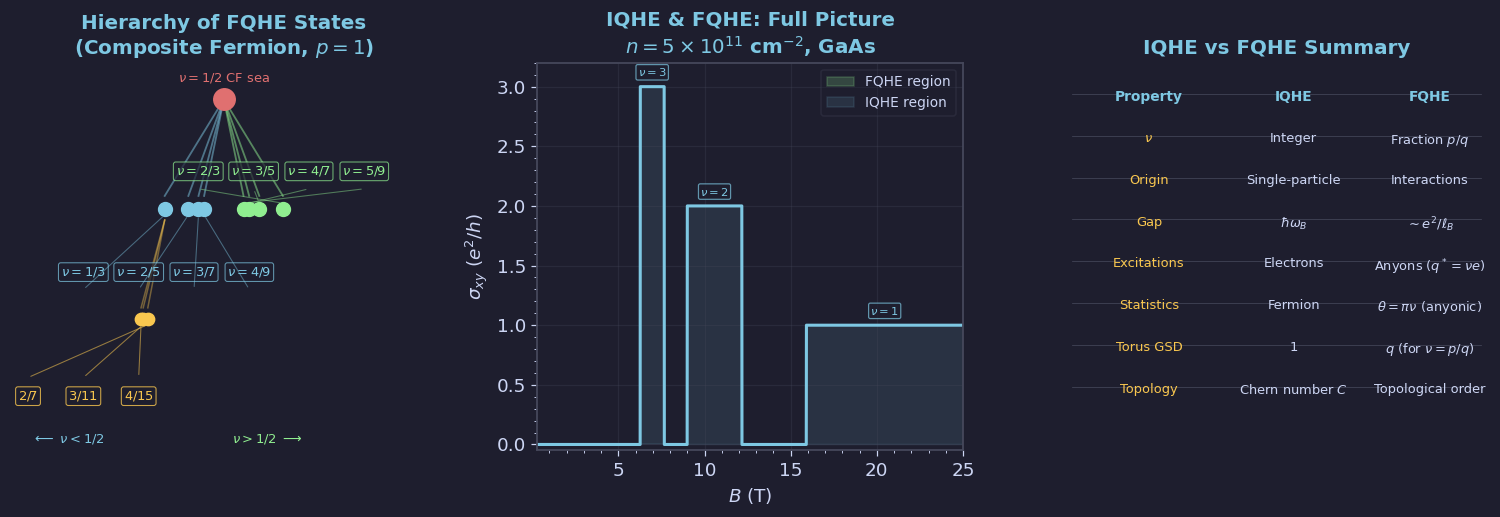

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import factorial
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
    'xtick.major.size':4,'ytick.major.size':4,
    'xtick.minor.visible':True,'ytick.minor.visible':True,
    'axes.linewidth':1.2,'lines.linewidth':2.2,
    'figure.dpi':110,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05 · Hierarchy & Key FQHE Summary ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Jain sequence hierarchy tree (p=1,2 fractions)
ax = axes[0]
ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.8, 4.5); ax.axis('off')
ax.set_title('Hierarchy of FQHE States\n(Composite Fermion, $p=1$)', color=BLUE)
# Root: nu=1/2 (CF Fermi sea)
ax.plot(0.5, 4.0, 'o', color=RED, ms=14, zorder=5)
ax.text(0.5, 4.25, r'$\nu=1/2$ CF sea', ha='center', color=RED, fontsize=8.5)
# Level 1: n=1,2,3,4 branches
level1_plus  = [1/3, 2/5, 3/7, 4/9]
level1_minus = [2/3, 3/5, 4/7, 5/9]
level1_all   = sorted(level1_plus + level1_minus)
y1 = 2.5
_lbl_fracs = {1/3:'1/3', 2/5:'2/5', 3/7:'3/7', 4/9:'4/9',
              2/3:'2/3', 3/5:'3/5', 4/7:'4/7', 5/9:'5/9'}
# 점과 연결선 먼저 그리기
for idx, nu_f in enumerate(level1_all):
    col = BLUE if nu_f < 0.5 else GREEN
    ax.plot(nu_f, y1, 'o', color=col, ms=9, zorder=5)
    ax.plot([0.5, nu_f], [4.0, y1 + 0.18], color=col, lw=1.2, alpha=0.5)

# 라벨을 점에서 분리해 위아래 전용 행에 배치
# BLUE(nu<0.5): y=1.85 아래 행에 4개 균등 배열
_plus_fracs = [1/3, 2/5, 3/7, 4/9]
_plus_lbls  = ['1/3', '2/5', '3/7', '4/9']
_plus_lx    = [0.17, 0.30, 0.43, 0.56]   # axes 좌표 (균등 배열)
_y_blue_ax  = 0.46                         # axes y 좌표 (하단 행)

# GREEN(nu>0.5): y=3.15 위 행에 4개 균등 배열
_minus_fracs = [2/3, 3/5, 4/7, 5/9]
_minus_lbls  = ['2/3', '3/5', '4/7', '5/9']
_minus_lx    = [0.44, 0.57, 0.70, 0.83]
_y_green_ax  = 0.72

for lx, lbl, nu_f in zip(_plus_lx, _plus_lbls, _plus_fracs):
    # 텍스트 (axes 좌표)
    ax.text(lx, _y_blue_ax, f'$\\nu={lbl}$',
            ha='center', va='center', color=BLUE, fontsize=8.5,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18', facecolor=BG,
                      edgecolor=BLUE, alpha=0.7, linewidth=0.7))
    # 인출선: axes → data 좌표 변환
    ax.annotate('', xy=(nu_f, y1 - 0.08),
                xytext=(lx, _y_blue_ax - 0.045),
                xycoords='data', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='-', color=BLUE,
                                lw=0.7, alpha=0.45))

for lx, lbl, nu_f in zip(_minus_lx, _minus_lbls, _minus_fracs):
    ax.text(lx, _y_green_ax, f'$\\nu={lbl}$',
            ha='center', va='center', color=GREEN, fontsize=8.5,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18', facecolor=BG,
                      edgecolor=GREEN, alpha=0.7, linewidth=0.7))
    ax.annotate('', xy=(nu_f, y1 + 0.08),
                xytext=(lx, _y_green_ax - 0.045),
                xycoords='data', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='-', color=GREEN,
                                lw=0.7, alpha=0.45))

# Level 2: Valid Jain daughters of 1/3 (p=2: n/(4n-1))
# 세 점(2/7=0.286, 3/11=0.273, 4/15=0.267)이 x축에서 0.02 범위 안에 몰려
# 점 바로 위에 라벨을 붙이면 필연적으로 겹침
# → BLUE/GREEN 라벨과 동일한 방식으로 별도 행(하단)에 균등 배열 + 인출선
sub_from_13 = [2/7, 3/11, 4/15]
y2 = 1.0
_sub_labels  = {2/7:'2/7', 3/11:'3/11', 4/15:'4/15'}
_sub_lx_ax   = [0.04, 0.17, 0.30]   # axes 좌표: 균등 배열
_y_yellow_ax = 0.14                  # axes y: BLUE 행 아래

for nu_f in sub_from_13:
    ax.plot(nu_f, y2, 'o', color=YELLOW, ms=8, zorder=5)
    ax.plot([1/3, nu_f], [y1 - 0.15, y2 + 0.15],
            color=YELLOW, lw=1.0, alpha=0.4)

for lx_ax, nu_f in zip(_sub_lx_ax, sub_from_13):
    # 라벨 텍스트 (axes 좌표)
    ax.text(lx_ax, _y_yellow_ax, f'${_sub_labels[nu_f]}$',
            ha='center', va='center', color=YELLOW, fontsize=8.5,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18', facecolor=BG,
                      edgecolor=YELLOW, alpha=0.8, linewidth=0.7))
    # 인출선: 라벨 → 점
    ax.annotate('', xy=(nu_f, y2 - 0.08),
                xytext=(lx_ax, _y_yellow_ax + 0.048),
                xycoords='data', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='-', color=YELLOW,
                                lw=0.7, alpha=0.55))
ax.text(0.05, 0.02, r'$\longleftarrow$ $\nu < 1/2$', ha='left',
        color=BLUE, fontsize=8.5, transform=ax.transAxes)
ax.text(0.52, 0.02, r'$\nu > 1/2$ $\longrightarrow$', ha='left',
        color=GREEN, fontsize=8.5, transform=ax.transAxes)

# Middle: sigma_xy vs B for FQHE (both IQHE and FQHE plateaux)
ax2 = axes[1]
B2 = np.linspace(0.3, 25, 5000)
n2d = 5e11 * 1e4   # m^-2  (5e11 cm^-2: FQHE plateaux fall within B range)
Phi0 = 4.136e-15
nu2 = n2d * Phi0 / B2
sig2 = np.zeros_like(B2)
# IQHE plateaux
for ni in [1, 2, 3]:
    sig2[np.abs(nu2 - ni) < 0.30] = ni
# FQHE plateaux (main ones)
for nf in [1/3, 2/3, 2/5, 3/5, 1/5]:
    sig2[np.abs(nu2 - nf) < 0.04] = nf
ax2.plot(B2, sig2, color=BLUE, lw=2.0)
# Shade FQHE plateaux in green
fqhe_mask = (sig2 > 0) & (sig2 < 1) | np.isin(sig2, [2/5, 3/5])
ax2.fill_between(B2, sig2, where=(sig2 > 0) & (sig2 < 0.99),
                 color=GREEN, alpha=0.2, label='FQHE region')
ax2.fill_between(B2, sig2, where=(sig2 >= 1),
                 color=BLUE, alpha=0.12, label='IQHE region')
ax2.set_xlabel('$B$ (T)')
ax2.set_ylabel(r'$\sigma_{xy}$ $(e^2/h)$')
ax2.set_title('IQHE & FQHE: Full Picture\n'
              r'$n=5\times10^{11}$ cm$^{-2}$, GaAs', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True); ax2.set_ylim(-0.05, 3.2); ax2.set_xlim(0.3, 25)
# 각 플래토 위에 직접 ν 값 레이블 — 플래토 구간 중앙 B에서 표시
_label_info = [
    (1/3, '1/3', GREEN), (2/3, '2/3', GREEN),
    (2/5, '2/5', GREEN), (3/5, '3/5', GREEN),
    (1,   '1',   BLUE),  (2,   '2',   BLUE), (3, '3', BLUE),
]
for nv, lab, col in _label_info:
    # 해당 플래토 구간의 B 배열 추출
    mask = (sig2 == nv)
    if mask.any():
        B_mid = 0.5 * (B2[mask].min() + B2[mask].max())
        ax2.text(B_mid, nv + 0.07, f'$\\nu={lab}$',
                 ha='center', va='bottom', color=col,
                 fontsize=7.5, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.15',
                           facecolor=BG, edgecolor=col, alpha=0.7, linewidth=0.8))

# Right: Summary comparison table (visual)
ax3 = axes[2]
ax3.axis('off')
ax3.set_title('IQHE vs FQHE Summary', color=BLUE)
table_data = [
    ['Property',           'IQHE',              'FQHE'],
    [r'$\nu$',             r'Integer',          r'Fraction $p/q$'],
    ['Origin',             'Single-particle',   'Interactions'],
    ['Gap',                r'$\hbar\omega_B$',  r'$\sim e^2/\ell_B$'],
    ['Excitations',        'Electrons',         r'Anyons ($q^*=\nu e$)'],
    ['Statistics',         r'Fermion',          r'$\theta=\pi\nu$ (anyonic)'],
    ['Torus GSD',          '1',                 r'$q$ (for $\nu=p/q$)'],
    ['Topology',           'Chern number $C$',  'Topological order'],
]
col_widths = [0.36, 0.32, 0.32]
col_x = [0.02, 0.38, 0.70]
row_h = 0.108
y_start = 0.93
for ri, row in enumerate(table_data):
    bg = BG if ri == 0 else (BLUE+'18' if ri % 2 == 0 else 'none')
    for ci, (cell, cx, cw) in enumerate(zip(row, col_x, col_widths)):
        col = BLUE if ri == 0 else (YELLOW if ci == 0 else FG)
        ax3.text(cx + cw/2, y_start - ri * row_h, cell,
                 transform=ax3.transAxes,
                 ha='center', va='top',
                 color=col,
                 fontsize=8.5 if ri > 0 else 9,
                 fontweight='bold' if ri == 0 else 'normal')
    y_line = y_start - ri * row_h - 0.01
    ax3.plot([0.02, 0.98], [y_line, y_line],
             color=EDGE, lw=0.5, transform=ax3.transAxes,
             clip_on=False)

plt.tight_layout(pad=1.5)
save('fig05_fqhe_summary.png', fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

zip_path = 'qhe_ch03_figures.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    for fname in sorted(os.listdir('figures/ch03')):
        fpath = os.path.join('figures/ch03', fname)
        zf.write(fpath, fname)
        print(f'  added {fname}')
print(f'\nCreated: {zip_path}')
files.download(zip_path)


  added fig01_fqhe_laughlin.png
  added fig02_plasma_quasihole.png
  added fig03_composite_fermions.png
  added fig04_anyons_topo_order.png
  added fig05_fqhe_summary.png

Created: qhe_ch03_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>